# 03 · Model iterations (tasks 9–12)
All models are tuned and compared on the **validation** set only. The test set stays held out
until the final evaluation (tasks 14–16).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline

from config import DATA_DIR, FIG_DIR, RESULTS_DIR, SEED, set_seeds
from src.metrics import RESULTS_CSV, evaluate, log_result

set_seeds()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RESULTS_CSV.unlink(missing_ok=True)  # fresh table each full run

d = np.load(DATA_DIR / "processed.npz")
Xtr, ytr = d["flat_train"], d["y_train"]
Xva, yva = d["flat_val"], d["y_val"]
Itr, Iva = d["img_train"], d["img_val"]
class_weights = {int(k): v for k, v in json.loads((DATA_DIR / "class_weights.json").read_text()).items()}
val_scores = {}  # model name -> validation scores, for the ROC figure
print(Xtr.shape, Xva.shape, Itr.shape, Iva.shape)

(4708, 784) (524, 784) (4708, 28, 28, 1) (524, 28, 28, 1)


## Iteration 0 · Majority-class baseline (task 9)

In [2]:
t0 = time.perf_counter()
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
secs = time.perf_counter() - t0
s = dummy.predict_proba(Xva)[:, 1]
val_scores["It0 majority"] = s
log_result("It0 majority", evaluate(yva, s), secs)

,model,auc,sensitivity,specificity,precision,f1,balanced_acc,accuracy,tn,fp,fn,tp,train_seconds
0,It0 majority,0.5,1.0,0.0,0.742366,0.852136,0.5,0.742366,0,135,0,389,0.0


## Iteration 1 · Logistic regression on raw pixels (task 10)
C chosen from {0.01, 0.1, 1} by validation AUC.

In [3]:
t0 = time.perf_counter()
best = None
for C in [0.01, 0.1, 1.0]:
    m = LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED).fit(Xtr, ytr)
    auc = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
    print(f"C={C:<5} val AUC={auc:.4f}")
    if best is None or auc > best[0]:
        best = (auc, C, m)
secs = time.perf_counter() - t0
logreg = best[2]
print("Chosen C:", best[1])
s = logreg.predict_proba(Xva)[:, 1]
val_scores["It1 logistic regression"] = s
log_result("It1 logistic regression", evaluate(yva, s), secs)

C=0.01  val AUC=0.9916
C=0.1   val AUC=0.9906


C=1.0   val AUC=0.9865
Chosen C: 0.01


,model,auc,sensitivity,specificity,precision,f1,balanced_acc,accuracy,tn,fp,fn,tp,train_seconds
0,It0 majority,0.50000,1.000000,0.000000,0.742366,0.852136,0.50000,0.742366,0,135,0,389,0.0
1,It1 logistic regression,0.99164,0.951157,0.962963,0.986667,0.968586,0.95706,0.954198,130,5,19,370,0.2


## Iteration 2 · PCA (50) → random forest (task 11)

In [4]:
t0 = time.perf_counter()
rf = make_pipeline(
    PCA(n_components=50, random_state=SEED),
    RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
).fit(Xtr, ytr)
secs = time.perf_counter() - t0
s = rf.predict_proba(Xva)[:, 1]
val_scores["It2 PCA + random forest"] = s
log_result("It2 PCA + random forest", evaluate(yva, s), secs)

,model,auc,sensitivity,specificity,precision,f1,balanced_acc,accuracy,tn,fp,fn,tp,train_seconds
0,It0 majority,0.500000,1.000000,0.000000,0.742366,0.852136,0.500000,0.742366,0,135,0,389,0.0
1,It1 logistic regression,0.991640,0.951157,0.962963,0.986667,0.968586,0.957060,0.954198,130,5,19,370,0.2
2,It2 PCA + random forest,0.987127,0.971722,0.925926,0.974227,0.972973,0.948824,0.959924,125,10,11,378,1.4


## Iteration 3 · Small CNN (task 12)
Light augmentation (small rotations and shifts, **no flips**), class weights, early stopping on validation AUC.

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)

def build_cnn():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.RandomRotation(0.05)(inputs)
    x = layers.RandomTranslation(0.1, 0.1)(x)
    for filters in (32, 64):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model

cnn = build_cnn()
cnn.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,057 (254.13 KB)

 Trainable params: 65,057 (254.13 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
t0 = time.perf_counter()
history = cnn.fit(
    Itr, ytr,
    validation_data=(Iva, yva),
    epochs=30,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True)],
    verbose=2,
)
secs = time.perf_counter() - t0
print(f"CNN training time: {secs:.0f} s ({len(history.history['loss'])} epochs)")
assert secs < 300, "CNN training exceeded the 5-minute budget"
cnn.save(RESULTS_DIR / "cnn.keras")
s = cnn.predict(Iva, verbose=0).ravel()
val_scores["It3 CNN"] = s
log_result("It3 CNN", evaluate(yva, s), secs)

Epoch 1/30


74/74 - 7s - 100ms/step - auc: 0.6179 - loss: 0.6709 - val_auc: 0.8359 - val_loss: 0.5672


Epoch 2/30


74/74 - 6s - 81ms/step - auc: 0.8262 - loss: 0.5151 - val_auc: 0.8998 - val_loss: 0.4897


Epoch 3/30


74/74 - 6s - 83ms/step - auc: 0.8865 - loss: 0.4275 - val_auc: 0.9396 - val_loss: 0.5960


... (52 outputs left out)

Epoch 30/30


74/74 - 7s - 89ms/step - auc: 0.9772 - loss: 0.1900 - val_auc: 0.9884 - val_loss: 0.4769


CNN training time: 196 s (30 epochs)


,model,auc,sensitivity,specificity,precision,f1,balanced_acc,accuracy,tn,fp,fn,tp,train_seconds
0,It0 majority,0.500000,1.000000,0.000000,0.742366,0.852136,0.500000,0.742366,0,135,0,389,0.0
1,It1 logistic regression,0.991640,0.951157,0.962963,0.986667,0.968586,0.957060,0.954198,130,5,19,370,0.2
2,It2 PCA + random forest,0.987127,0.971722,0.925926,0.974227,0.972973,0.948824,0.959924,125,10,11,378,1.4
3,It3 CNN,0.992059,0.773779,0.992593,0.996689,0.871201,0.883186,0.830153,134,1,88,301,196.1


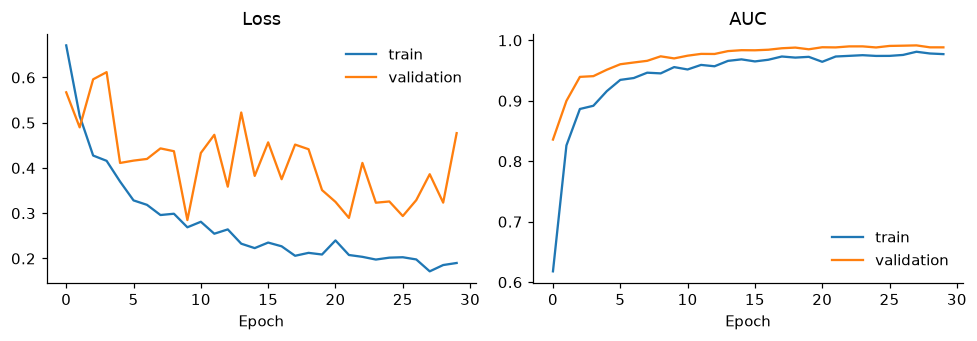

In [7]:
h = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(h.loss, label="train"); axes[0].plot(h.val_loss, label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(frameon=False)
axes[1].plot(h.auc, label="train"); axes[1].plot(h.val_auc, label="validation")
axes[1].set_title("AUC"); axes[1].set_xlabel("Epoch"); axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_cnn_learning_curves.png")
plt.show()

## Comparison on the validation set (threshold 0.5)

In [8]:
results = pd.read_csv(RESULTS_CSV)
cols = ["model", "auc", "sensitivity", "specificity", "precision", "f1", "balanced_acc", "accuracy", "train_seconds"]
results[cols].round(3)

,model,auc,sensitivity,specificity,precision,f1,balanced_acc,accuracy,train_seconds
0,It0 majority,0.500,1.000,0.000,0.742,0.852,0.500,0.742,0.0
1,It1 logistic regression,0.992,0.951,0.963,0.987,0.969,0.957,0.954,0.2
2,It2 PCA + random forest,0.987,0.972,0.926,0.974,0.973,0.949,0.960,1.4
3,It3 CNN,0.992,0.774,0.993,0.997,0.871,0.883,0.830,196.1


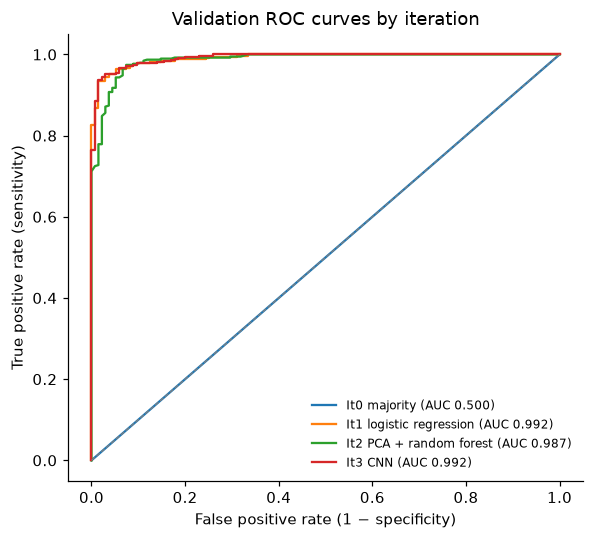

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, s in val_scores.items():
    fpr, tpr, _ = roc_curve(yva, s)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yva, s):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8)
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("Validation ROC curves by iteration")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig8_val_roc.png")
plt.show()

## Findings (validation set)
- **It0 → It1:** logistic regression on raw pixels jumps from AUC 0.50 to 0.992, so the classes are close to
  linearly separable at 28×28, as the PCA scatter in 01_eda suggested.
- **It2:** PCA + random forest does not beat it (AUC 0.987). Compressing to 50 components loses a little signal.
- **It3:** the CNN matches logistic regression on AUC (0.992) but does not clearly beat it. Validation AUC
  is near its ceiling, so the models differ little here; the shifted test set (01_eda) is where differences
  should show.
- **CNN threshold:** at the default 0.5 threshold the CNN's sensitivity is only 0.77 (88 missed pneumonia
  cases), even though its ranking (AUC) is excellent. Class weighting pushes its scores towards "normal", so
  0.5 is the wrong cut-off. Task 15 picks the threshold on validation for at least 95% sensitivity.
- **Budget:** the CNN ran all 30 epochs in about 3.3 min without early stopping triggering, within the 5-min budget.